# Machine Learning Workflow: Student AI-Assistant Repeat Use
**Course:** IoT — Level 4  
**Student name:** Malak Ashraf  
**Student ID:** 4221162

This notebook completes dataset exploration, preprocessing, splitting, model training and evaluation. The selected file is **data5.zip.zip → ai_assistant_usage_student_life.csv** from the [provided Google Drive folder](https://drive.google.com/drive/folders/1PpRWGKMmeWOwtv3E2Ut4kAsZf5Zjk9BS).

**Question:** Can information recorded at the end of an AI-assistant session predict the dataset's `UsedAgain` label (No / Yes)? This is binary classification. Satisfaction and session outcome are assumed available before repeat use is observed. No data dictionary was supplied for this file, so this timing is an assumption, not a verified property of the data.

**Run:** Keep the CSV beside this notebook, install packages from `requirements.txt`, select a Python 3 kernel, then **Restart Kernel and Run All**. Outputs below were generated by executing the notebook.

## Task 1 — Dataset selection and exploration

The folder offers social-media engagement (data1), airline loyalty (data2), job advertisements (data3), EV specifications (data4), and student AI usage (data5). Data5 is selected because it provides a direct binary target, 10,000 observations and a manageable mix of numeric and categorical features. It demonstrates the required workflow without table joins or text classification. No claim is made that it contains IoT sensor measurements.

A row represents a session, not necessarily a unique student. The dataset does not provide a stable student identifier or a documented repeat-use observation window.

In [1]:
from pathlib import Path
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, classification_report, f1_score,
                             ConfusionMatrixDisplay)

SEED = 42
DATA_PATH = Path("ai_assistant_usage_student_life.csv")
if not DATA_PATH.is_file():
    raise FileNotFoundError("Place ai_assistant_usage_student_life.csv beside this notebook.")
print("Python:", platform.python_version(), "| scikit-learn:", sklearn.__version__)
print("Dataset SHA-256:", hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,}; columns: {df.shape[1]}")
display(df.head())

Python: 3.12.3 | scikit-learn: 1.9.1
Dataset SHA-256: cb944ad93cac062da7293b708cac0ae678fcc74fd7b23d9dd5e4de4e968befd5
Rows: 10,000; columns: 11


,SessionID,StudentLevel,Discipline,SessionDate,SessionLengthMin,TotalPrompts,TaskType,AI_AssistanceLevel,FinalOutcome,UsedAgain,SatisfactionRating
0,SESSION00001,Undergraduate,Computer Science,2024-11-03,31.20,11,Studying,2,Assignment Completed,True,1.0
1,SESSION00002,Undergraduate,Psychology,2024-08-25,13.09,6,Studying,3,Assignment Completed,True,2.0
2,SESSION00003,Undergraduate,Business,2025-01-12,19.22,5,Coding,3,Assignment Completed,True,3.3
3,SESSION00004,Undergraduate,Computer Science,2025-05-06,3.70,1,Coding,3,Assignment Completed,True,3.5
4,SESSION00005,Undergraduate,Psychology,2025-03-18,28.12,9,Writing,3,Assignment Completed,True,2.9


In [2]:
df.info()
display(df.describe(include="all").T)
quality = pd.DataFrame({"dtype": df.dtypes.astype(str),
                        "missing": df.isna().sum(),
                        "unique_values": df.nunique()})
display(quality)
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated session IDs:", df["SessionID"].duplicated().sum())
display(df["UsedAgain"].value_counts(dropna=False).rename("sessions"))

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   SessionID           10000 non-null  str    
 1   StudentLevel        10000 non-null  str    
 2   Discipline          10000 non-null  str    
 3   SessionDate         10000 non-null  str    
 4   SessionLengthMin    10000 non-null  float64
 5   TotalPrompts        10000 non-null  int64  
 6   TaskType            10000 non-null  str    
 7   AI_AssistanceLevel  10000 non-null  int64  
 8   FinalOutcome        10000 non-null  str    
 9   UsedAgain           10000 non-null  bool   
 10  SatisfactionRating  10000 non-null  float64
dtypes: bool(1), float64(2), int64(2), str(6)
memory usage: 791.1 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
SessionID,10000,10000,SESSION00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StudentLevel,10000,3,Undergraduate,5978,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Discipline,10000,7,Biology,1458,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SessionDate,10000,366,2025-06-21,41,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SessionLengthMin,10000.0,NaN,NaN,NaN,19.846467,13.897302,0.03,9.63,16.65,26.67,110.81
TotalPrompts,10000.0,NaN,NaN,NaN,5.6075,4.648764,1.0,2.0,4.0,8.0,39.0
TaskType,10000,6,Writing,3101,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AI_AssistanceLevel,10000.0,NaN,NaN,NaN,3.4795,0.991805,1.0,3.0,4.0,4.0,5.0
FinalOutcome,10000,4,Assignment Completed,4768,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UsedAgain,10000,2,True,7064,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,dtype,missing,unique_values
SessionID,str,0,10000
StudentLevel,str,0,3
Discipline,str,0,7
SessionDate,str,0,366
SessionLengthMin,float64,0,4078
TotalPrompts,int64,0,37
TaskType,str,0,6
AI_AssistanceLevel,int64,0,5
FinalOutcome,str,0,4
UsedAgain,bool,0,2


Exact duplicate rows: 0
Repeated session IDs: 0


UsedAgain
True     7064
False    2936
Name: sessions, dtype: int64

## Task 2 — Data preprocessing

- Keep `UsedAgain` as the target; map False/True to 0/1. Never impute an unknown target.
- Exclude `SessionID`: it identifies a record rather than describing behavior.
- Exclude `SessionDate`: this experiment studies session attributes rather than calendar effects. A future forecasting study should use a chronological split.
- Retain session-level numeric attributes and categorical context. Satisfaction and outcome are appropriate only for the stated end-of-session prediction scenario.
- Remove exact repeated predictor/target records before splitting, so duplicate copies cannot cross the split. Reject contradictory labels for identical predictors rather than silently resolving them.
- Numeric features: median imputation followed by standard scaling. Categorical features: most-frequent imputation and one-hot encoding with unseen categories ignored.

All learned imputation, scaling and encoding are fitted inside a pipeline **on training data only**, including inside each cross-validation fold. The original CSV has no missing values; imputation is included to make the workflow explicit and reusable. Valid extreme session lengths are retained rather than removed arbitrarily.

In [3]:
TARGET = "UsedAgain"
NUMERIC = ["SessionLengthMin", "TotalPrompts", "AI_AssistanceLevel", "SatisfactionRating"]
CATEGORICAL = ["StudentLevel", "Discipline", "TaskType", "FinalOutcome"]
FEATURES = NUMERIC + CATEGORICAL
assert set(FEATURES + [TARGET, "SessionID", "SessionDate"]).issubset(df.columns)

clean = df.copy()
for col in CATEGORICAL:
    clean[col] = clean[col].str.strip().replace("", np.nan)
for col in NUMERIC:
    clean[col] = pd.to_numeric(clean[col], errors="coerce").replace([np.inf, -np.inf], np.nan)
labels = clean[TARGET].astype("string").str.strip().str.lower()
unknown = labels.notna() & ~labels.isin(["true", "false"])
if unknown.any():
    raise ValueError(f"Unexpected target labels: {labels[unknown].unique()}")
print("Rows removed for missing target:", int(labels.isna().sum()))
clean[TARGET] = labels.map({"false": 0, "true": 1})
clean = clean.dropna(subset=[TARGET]).copy()
clean[TARGET] = clean[TARGET].astype(int)
before = len(clean)
clean = clean.drop_duplicates(subset=FEATURES + [TARGET]).reset_index(drop=True)
print("Repeated predictor/target rows removed:", before - len(clean))
if clean.duplicated(subset=FEATURES, keep=False).any():
    raise ValueError("Identical predictors have conflicting labels; investigate before splitting.")
X = clean[FEATURES].copy()
y = clean[TARGET].copy()
assert y.nunique() == 2
print("Predictor shape:", X.shape)
display(X.isna().sum().rename("missing values after deterministic cleaning"))

Rows removed for missing target: 0
Repeated predictor/target rows removed: 0
Predictor shape: (10000, 8)


SessionLengthMin      0
TotalPrompts          0
AI_AssistanceLevel    0
SatisfactionRating    0
StudentLevel          0
Discipline            0
TaskType              0
FinalOutcome          0
Name: missing values after deterministic cleaning, dtype: int64

## Task 3 — Data splitting

Use an **80% training / 20% testing** stratified split with `random_state=42`. Stratification preserves the proportions of Yes and No. Training data is also used for five-fold stratified cross-validation; the test set is reserved for the final evaluation.

This estimates performance for randomly held-out sessions from the same source. It does not establish performance on new students or future dates: student grouping and a chronological holdout would be needed for those claims.

Training rows: 8,000; testing rows: 2,000


,train_count,test_count,train_fraction,test_fraction
UsedAgain,,,,
Yes,5651,1413,0.706375,0.7065
No,2349,587,0.293625,0.2935


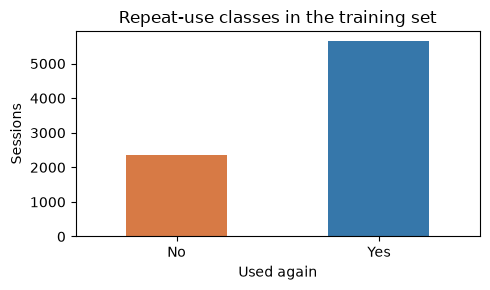

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(X)
print(f"Training rows: {len(X_train):,}; testing rows: {len(X_test):,}")
split_summary = pd.DataFrame({
    "train_count": y_train.value_counts(), "test_count": y_test.value_counts(),
    "train_fraction": y_train.value_counts(normalize=True),
    "test_fraction": y_test.value_counts(normalize=True)
}).rename(index={0: "No", 1: "Yes"})
display(split_summary)

fig, ax = plt.subplots(figsize=(5, 3))
y_train.value_counts().sort_index().rename(index={0: "No", 1: "Yes"}).plot.bar(
    ax=ax, color=["#d77a45", "#3677aa"], rot=0)
ax.set(title="Repeat-use classes in the training set", xlabel="Used again", ylabel="Sessions")
plt.tight_layout()
plt.show()

In [5]:
numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, NUMERIC),
    ("categorical", categorical_pipeline, CATEGORICAL)
])

## Task 4 — Model selection and training

Compare two conventional classifiers:

1. **Logistic regression:** a simple baseline with scaled numeric inputs and one-hot categorical inputs.
2. **Random forest:** captures nonlinear relationships and interactions. Restrict depth and leaf size to reduce overfitting.

Use class weighting to give minority-class errors more influence. Choose between these models by **mean five-fold cross-validation macro F1** on the training set. Macro F1 weights both classes equally, making it more informative here than accuracy alone. Model settings and this selection rule are specified before examining test performance.

A separate majority-class dummy provides a reference: high accuracy is possible just by predicting Yes for everyone. No test-set tuning is performed.

In [6]:
candidates = {
    "Logistic regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
    "Random forest": RandomForestClassifier(
        n_estimators=150, max_depth=8, min_samples_leaf=5,
        class_weight="balanced_subsample", random_state=SEED, n_jobs=1
    )
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for name, estimator in candidates.items():
    pipeline = Pipeline([("preprocess", clone(preprocessor)), ("model", clone(estimator))])
    scores = cross_validate(pipeline, X_train, y_train, cv=cv,
                            scoring={"accuracy": "accuracy", "macro_f1": "f1_macro"},
                            n_jobs=1, error_score="raise")
    cv_rows.append({"model": name, "CV accuracy": scores["test_accuracy"].mean(),
                    "CV macro F1": scores["test_macro_f1"].mean(),
                    "CV macro F1 std": scores["test_macro_f1"].std()})
cv_results = pd.DataFrame(cv_rows).set_index("model").sort_values("CV macro F1", ascending=False)
display(cv_results.round(4))
best_name = cv_results.index[0]
model = Pipeline([("preprocess", clone(preprocessor)),
                  ("model", clone(candidates[best_name]))])
model.fit(X_train, y_train)
print("Selected using training CV only:", best_name)
print("Encoded feature count:", len(model.named_steps["preprocess"].get_feature_names_out()))

,CV accuracy,CV macro F1,CV macro F1 std
model,,,
Logistic regression,0.7546,0.6849,0.0130
Random forest,0.7544,0.6849,0.0133


Selected using training CV only: Logistic regression
Encoded feature count: 24


## Task 5 — Model evaluation

Evaluate once on the held-out test set. The classification report contains **precision**, **recall**, **F1-score**, and **support** for both classes:

- Precision: among predicted members of a class, the fraction classified correctly.
- Recall: among actual members of a class, the fraction identified correctly.
- F1: the harmonic mean of precision and recall.
- Support: the number of actual test examples in that class.

Rows of the confusion matrix are actual classes and columns are predictions. The macro averages give equal weight to each class; weighted averages give more weight to the majority class.

In [7]:
y_pred = model.predict(X_test)
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
comparison = pd.DataFrame([
    {"model": "Always predict training majority", "accuracy": accuracy_score(y_test, baseline_pred),
     "macro F1": f1_score(y_test, baseline_pred, average="macro", zero_division=0)},
    {"model": best_name, "accuracy": accuracy_score(y_test, y_pred),
     "macro F1": f1_score(y_test, y_pred, average="macro", zero_division=0)}
]).set_index("model")
display(comparison.round(4))
accuracy = accuracy_score(y_test, y_pred)
print(f"Selected model test accuracy: {accuracy:.4f} ({accuracy:.2%})")
print(classification_report(y_test, y_pred, labels=[0, 1], target_names=["No", "Yes"],
                            digits=4, zero_division=0))
report = classification_report(y_test, y_pred, labels=[0, 1], target_names=["No", "Yes"],
                               output_dict=True, zero_division=0)
report_table = pd.DataFrame(report).T
display(report_table.round(4))
assert int(report["No"]["support"] + report["Yes"]["support"]) == len(y_test)
assert np.isclose(accuracy, (np.asarray(y_test) == y_pred).mean())

,accuracy,macro F1
model,,
Always predict training majority,0.7065,0.4140
Logistic regression,0.7425,0.6701


Selected model test accuracy: 0.7425 (74.25%)
              precision    recall  f1-score   support

          No     0.5756    0.4668    0.5155       587
         Yes     0.7946    0.8570    0.8247      1413

    accuracy                         0.7425      2000
   macro avg     0.6851    0.6619    0.6701      2000
weighted avg     0.7303    0.7425    0.7339      2000



,precision,recall,f1-score,support
No,0.5756,0.4668,0.5155,587.0000
Yes,0.7946,0.8570,0.8247,1413.0000
accuracy,0.7425,0.7425,0.7425,0.7425
macro avg,0.6851,0.6619,0.6701,2000.0000
weighted avg,0.7303,0.7425,0.7339,2000.0000


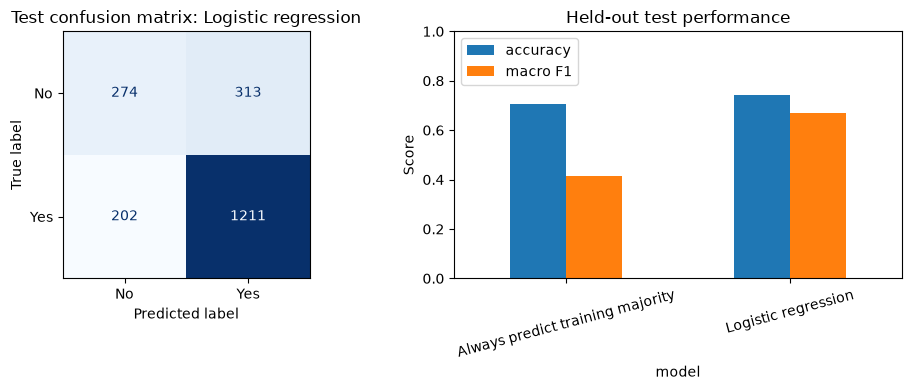

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=[0, 1],
    display_labels=["No", "Yes"], cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"Test confusion matrix: {best_name}")
comparison[["accuracy", "macro F1"]].plot.bar(ax=axes[1], rot=15)
axes[1].set(title="Held-out test performance", ylabel="Score", ylim=(0, 1))
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

## Conclusion

The following discussion is calculated from the actual execution results, so it remains consistent when the notebook is rerun.

In [9]:
baseline_accuracy = accuracy_score(y_test, baseline_pred)
macro_f1 = report["macro avg"]["f1-score"]
baseline_f1 = f1_score(y_test, baseline_pred, average="macro", zero_division=0)
accuracy_comment = ("exceeds" if accuracy > baseline_accuracy else "does not exceed")
f1_comment = ("improves on" if macro_f1 > baseline_f1 else "does not improve on")
display(Markdown(f"""
The selected model is **{best_name}**, chosen by training cross-validation macro F1.
On **{len(y_test):,} held-out sessions**, it obtains **{accuracy:.2%} accuracy** and
**{macro_f1:.4f} macro F1**. Its accuracy {accuracy_comment} the majority baseline
(**{baseline_accuracy:.2%}**), while its macro F1 {f1_comment} the baseline (**{baseline_f1:.4f}**).

For **No**, precision is **{report['No']['precision']:.4f}**, recall is
**{report['No']['recall']:.4f}**, and F1 is **{report['No']['f1-score']:.4f}**
(support: **{int(report['No']['support'])}**). For **Yes**, precision is
**{report['Yes']['precision']:.4f}**, recall is **{report['Yes']['recall']:.4f}**,
and F1 is **{report['Yes']['f1-score']:.4f}** (support: **{int(report['Yes']['support'])}**).
These class-level results matter because the majority baseline never detects No.

Class weighting trades performance between the classes; a higher macro F1 does not
necessarily mean higher accuracy. The cross-validation scores and held-out results
should be judged against the baseline, rather than treating completion of training
as proof that the model is useful.

**Limitations:** the supplied file has no accompanying data dictionary verifying
how repeat use was measured or when satisfaction was collected. The results show
association, not causation. Sessions may belong to the same student, which cannot
be checked without a student identifier. A random session split does not measure
future performance. Before practical use, verify label timing and provenance,
collect student identifiers and repeat-use windows, and validate on future dates
and unseen students. For a prediction before a session ends, remove satisfaction,
final outcome and other features not yet available, then retrain and evaluate.
"""))


The selected model is **Logistic regression**, chosen by training cross-validation macro F1.
On **2,000 held-out sessions**, it obtains **74.25% accuracy** and
**0.6701 macro F1**. Its accuracy exceeds the majority baseline
(**70.65%**), while its macro F1 improves on the baseline (**0.4140**).

For **No**, precision is **0.5756**, recall is
**0.4668**, and F1 is **0.5155**
(support: **587**). For **Yes**, precision is
**0.7946**, recall is **0.8570**,
and F1 is **0.8247** (support: **1413**).
These class-level results matter because the majority baseline never detects No.

Class weighting trades performance between the classes; a higher macro F1 does not
necessarily mean higher accuracy. The cross-validation scores and held-out results
should be judged against the baseline, rather than treating completion of training
as proof that the model is useful.

**Limitations:** the supplied file has no accompanying data dictionary verifying
how repeat use was measured or when satisfaction was collected. The results show
association, not causation. Sessions may belong to the same student, which cannot
be checked without a student identifier. A random session split does not measure
future performance. Before practical use, verify label timing and provenance,
collect student identifiers and repeat-use windows, and validate on future dates
and unseen students. For a prediction before a session ends, remove satisfaction,
final outcome and other features not yet available, then retrain and evaluate.
